# 17 — CartPole: DQN과 Double DQN

두 알고리즘은 같은 네트워크·Adam·Replay·Seed와 고정 환경 step 예산을 사용한다. 차이는 다음 행동을 Online Q로 선택하고 Target Q로 평가하는 Double DQN Bootstrap이다. Dueling DQN을 뜻하지 않는다. Target 수식은 Learner가 담당한다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl import Model
from modular_rl import representations as R, estimators as E, selectors as S
from modular_rl import buffers as B, targets as T, updates as U, learners as L
from modular_rl.data import Transition, Episode
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

Matplotlib is building the font cache; this may take a moment.


{'mode': 'FULL', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


### 통제한 예산과 컴포넌트
각 알고리즘을 독립적으로 초기화한다. 같은 Seed는 같은 경험을 보장하지 않는다. 환경 step, Warm-up, Batch 크기, Gradient Update 수, Target Sync 수를 같게 맞춘다. 마지막 예산 경계는 실제 마지막 관측을 가진 외부 Truncation으로 기록한다.

`L.DoubleDQN`은 `TransitionBatch`와 `SequenceBatch`를 모두 지원한다. n-step에는 기존 `B.SequenceReplay`와 `T.NStep`을 사용하며 Return 계산을 다시 작성하지 않는다. Online Bootstrap은 임시 eval/no_grad이고 원래 모드는 복원한다.

DQN episodes 100 steps 1968 return 15.0 updates 969 target_syncs 7


DQN episodes 200 steps 4884 return 114.0 updates 3885 target_syncs 19


DQN episodes 300 steps 17648 return 107.0 updates 16649 target_syncs 70


DQN episodes 400 steps 35232 return 159.0 updates 34233 target_syncs 140


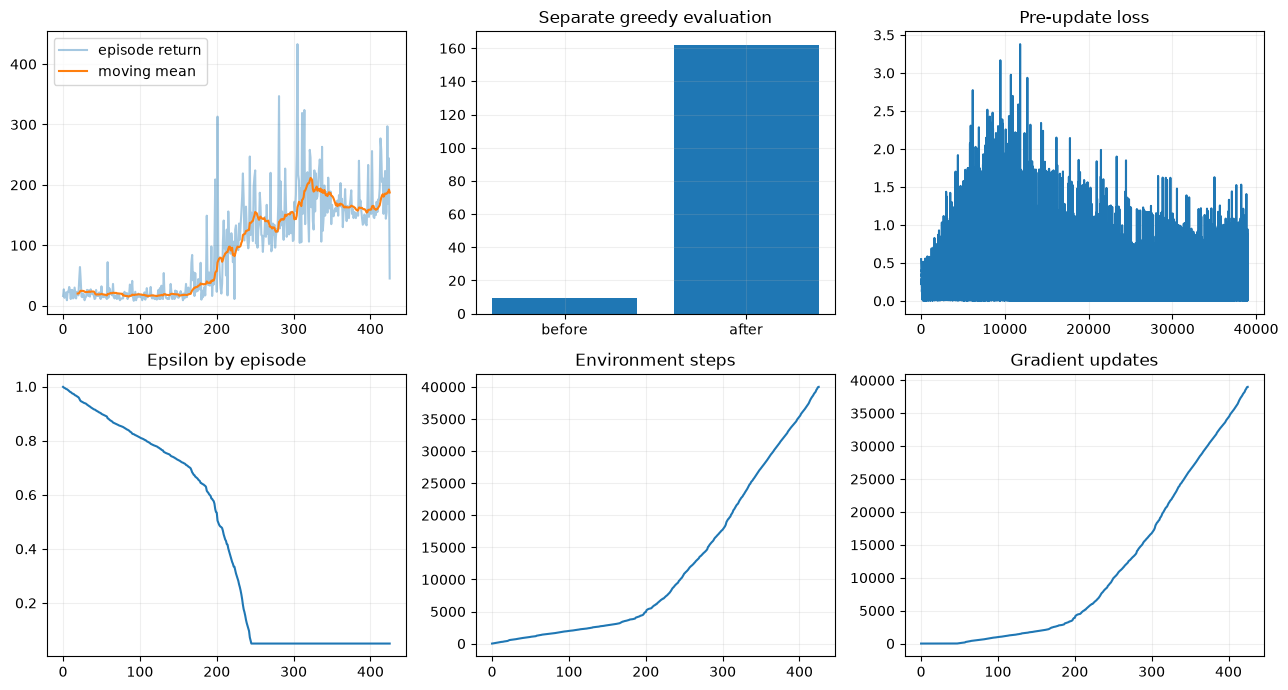

RESULT {"after": 162.1, "before": 9.2, "environment_steps": 40000, "episodes": 426, "gradient_updates": 39001, "last_loss": 0.019843731075525284}
DQN {"after": 162.1, "algorithm": "DQN", "before": 9.2, "environment_steps": 40000, "episodes": 426, "gradient_updates": 39001, "last_loss": 0.019843731075525284, "replay_reuse": true, "target_syncs": 160}


Double DQN episodes 100 steps 1990 return 24.0 updates 991 target_syncs 7


Double DQN episodes 200 steps 6052 return 147.0 updates 5053 target_syncs 24


Double DQN episodes 300 steps 21395 return 180.0 updates 20396 target_syncs 85


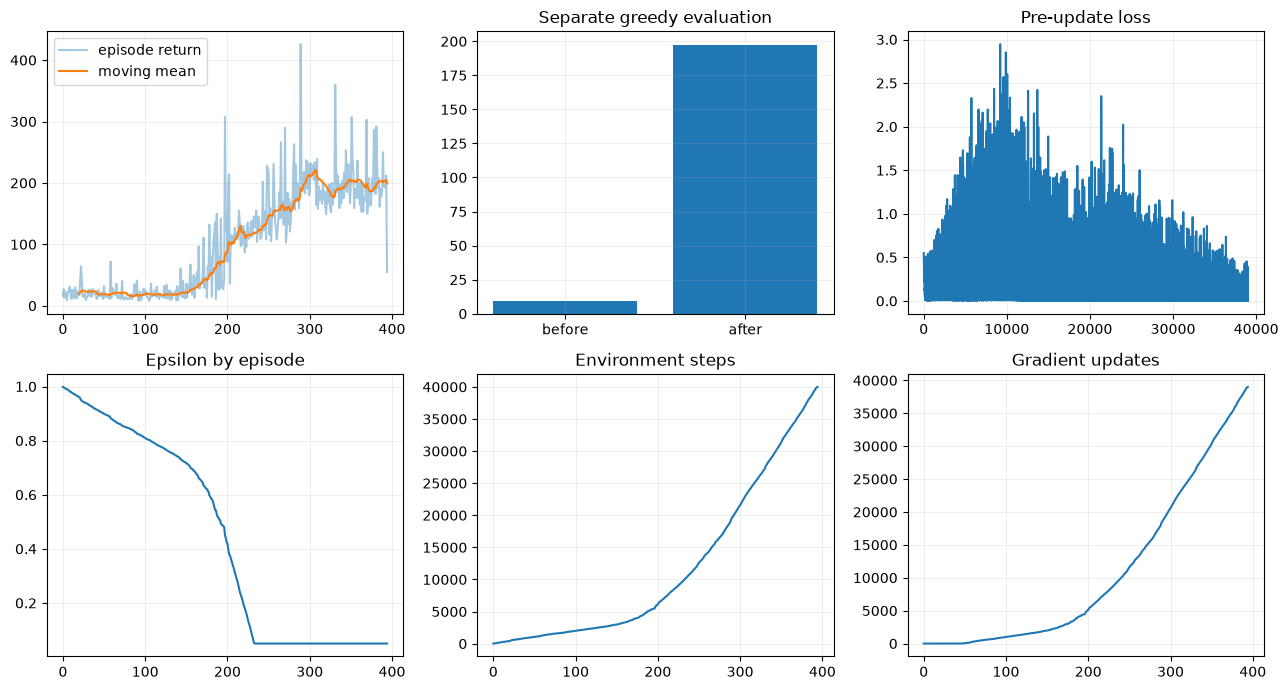

RESULT {"after": 197.45, "before": 9.2, "environment_steps": 40000, "episodes": 395, "gradient_updates": 39001, "last_loss": 0.005252968519926071}
Double DQN {"after": 197.45, "algorithm": "Double DQN", "before": 9.2, "environment_steps": 40000, "episodes": 395, "gradient_updates": 39001, "last_loss": 0.005252968519926071, "replay_reuse": true, "target_syncs": 160}


In [2]:
STEP_BUDGET = 400 if FAST else 40000
BATCH_SIZE, WARMUP = (16,32) if FAST else (64,1000)
SYNC_STEPS = 250
results = {}
for label, learner_type in [('DQN', L.DQN), ('Double DQN', L.DoubleDQN)]:
    torch.manual_seed(SEED)
    env = gym.make('CartPole-v1', max_episode_steps=60 if FAST else 500)
    eval_env = gym.make('CartPole-v1')
    representation = R.MLP(4, hidden_dims=(128,128))
    selector = S.EpsilonGreedy(1.)
    model = Model(representation, E.DiscreteQ(128,2), selector)
    target_model = deepcopy(model)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
    learner = learner_type(model, target_model, optimizer, T.TD0(GAMMA),
                           U.TDLoss(nn.SmoothL1Loss(reduction='none')))
    learner.sync_target()
    buffer = B.Replay(10000, seed=SEED)
    model.eval()
    before = evaluate(eval_env, lambda observation: model.act(observation, deterministic=True).action.item(),
                      episodes=3 if FAST else 20, seed=SEED+1000)
    model.train()
    log, losses, epsilons, updates = history(), [], [], []
    gradient_updates = target_syncs = 0
    observation, _ = env.reset(seed=SEED)
    total, length = 0., 0
    try:
        for steps in range(1, STEP_BUDGET+1):
            selector.epsilon = max(.05, 1.-.95*(steps-1)/(500 if FAST else 10000))
            selected = model.act(observation)
            next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
            cutoff = steps == STEP_BUDGET and not (terminated or truncated)
            truncated = truncated or cutoff
            buffer.add(observation, selected.action, float(reward), next_observation, terminated, truncated)
            if len(buffer) >= WARMUP:
                result = learner.learn(buffer.sample(BATCH_SIZE))
                losses.append(result.loss.item()); gradient_updates += 1
            if steps % SYNC_STEPS == 0:
                learner.sync_target(); target_syncs += 1
            total += reward; length += 1
            observation = next_observation
            if terminated or truncated:
                record(log, total, length, terminated, truncated)
                epsilons.append(selector.epsilon); updates.append(gradient_updates)
                if len(log['rewards']) % (10 if FAST else 100) == 0:
                    print(label, 'episodes', len(log['rewards']), 'steps', steps, 'return', total,
                          'updates', gradient_updates, 'target_syncs', target_syncs)
                if steps < STEP_BUDGET:
                    observation, _ = env.reset()
                    total, length = 0., 0
        model.eval()
        after = evaluate(eval_env, lambda observation: model.act(observation, deterministic=True).action.item(),
                         episodes=3 if FAST else 20, seed=SEED+1000)
        summary = neural_report(log, losses, epsilons, updates, before, after)
        summary.update(target_syncs=target_syncs, replay_reuse=True, algorithm=label)
        results[label] = dict(summary=summary, log=log, losses=losses, epsilons=epsilons, updates=updates,
                              online_state=deepcopy(model.state_dict()), target_state=deepcopy(target_model.state_dict()),
                              optimizer_state=deepcopy(optimizer.state_dict()), replay_rng=deepcopy(buffer._rng.bit_generator.state))
        print(label, json.dumps(summary, sort_keys=True))
    finally:
        env.close(); eval_env.close()

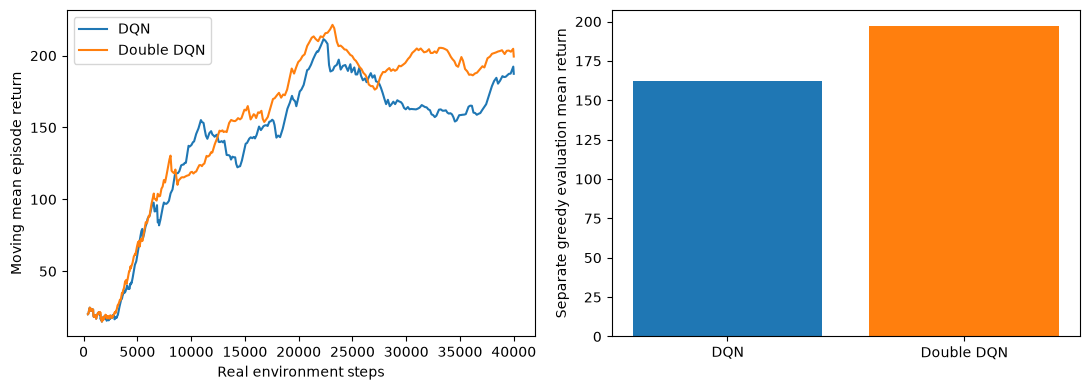

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11,4))
for label, run in results.items():
    lengths = np.asarray(run['log']['lengths'])
    rewards = np.asarray(run['log']['rewards'])
    window = min(20, len(rewards))
    mean = np.convolve(rewards, np.ones(window)/window, mode='valid')
    axes[0].plot(np.cumsum(lengths)[window-1:], mean, label=label)
    axes[1].bar(label, run['summary']['after'])
axes[0].set(xlabel='Real environment steps', ylabel='Moving mean episode return')
axes[0].legend(); axes[1].set_ylabel('Separate greedy evaluation mean return')
fig.tight_layout(); plt.show()
assert results['DQN']['summary']['environment_steps'] == results['Double DQN']['summary']['environment_steps']
assert results['DQN']['summary']['gradient_updates'] == results['Double DQN']['summary']['gradient_updates']
assert results['DQN']['summary']['target_syncs'] == results['Double DQN']['summary']['target_syncs']

### 해석과 Checkpoint
이 결과는 Seed 7의 두 독립 학습 실행이다. 단일 Seed로 알고리즘 우열을 일반화하지 않는다. 환경 step과 업데이트 예산을 맞춰도 행동과 Replay 내용은 달라진다. DQN/Double DQN 모두 Model·Target·Optimizer·Replay RNG·행동 RNG와 외부 스케줄을 저장해야 재개할 수 있다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.